<center><h1> <b> Object Detection Using YOLO <b> </h1></center>

In [1]:
import os

from google.colab import drive
drive.mount('/content/drive')
try: os.makedirs('/content/drive/MyDrive/Colab_Notebooks')
except Exception as e:
    print("Directory already exist", e)
%cd '/content/drive/MyDrive/Colab_Notebooks'
!ls

Mounted at /content/drive
Directory already exist [Errno 17] File exists: '/content/drive/MyDrive/Colab_Notebooks'
/content/drive/MyDrive/Colab_Notebooks
Cycling_Hand_Signals_Dataset


Importing required Libraries

In [16]:
from PIL import Image
from tensorflow import keras
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import tensorflow as tf
import cv2
import seaborn as sns
import glob
import xml.etree.ElementTree as ET
import os
import shutil
import pandas as pd

# Dataset Description






# Data  

### Classification:  
0: Caution  
1: Cyclist  
2: Left Turn  
3: Right Turn  
4: Stop

In [8]:
# Download Dataset, contains test, train, valid
!wget -q https://github.com/zhengyangsu/Computer-Vision-Project-Overview/releases/download/v1.0/Cycling_Hand_Signals_Dataset.zip -O tmp.zip
!unzip -q tmp.zip -d /content/drive/MyDrive/Colab_Notebooks/Cycling_Hand_Signals_Dataset && rm tmp.zip
!ls /content/drive/MyDrive/Colab_Notebooks/Cycling_Hand_Signals_Dataset


replace /content/drive/MyDrive/Colab_Notebooks/Cycling_Hand_Signals_Dataset/data.yaml? [y]es, [n]o, [A]ll, [N]one, [r]ename: A

data.yaml  README.roboflow.txt	test  train  valid


# Data Preprocessing

For preprocessing:
- We have to convert the dataset into that acceptable by YOLO.
  - Heirarchy of folders should be the one accepted by YOLO
  - Labels format should be darknet YOLO.
  - Labels files should be .txt files
- Check and see if there are any missing labels or images. And remove them from dataset.


## Heirarchy of Folders correction

Defining paths to train and test folders.

In [11]:
data_dir = '/content/drive/MyDrive/Colab_Notebooks/Cycling_Hand_Signals_Dataset'

train_dir = f'{data_dir}/train'
valid_dir = f'{data_dir}/valid'
test_dir  = f'{data_dir}/test'

print(train_dir)
print(valid_dir)
print(test_dir)

/content/drive/MyDrive/Colab_Notebooks/Cycling_Hand_Signals_Dataset/train
/content/drive/MyDrive/Colab_Notebooks/Cycling_Hand_Signals_Dataset/valid
/content/drive/MyDrive/Colab_Notebooks/Cycling_Hand_Signals_Dataset/test




The train and test folders have all the images and labels together.

But for YOLO, the directories should be in:

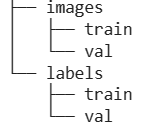


Making directories according to above struture of folders

In [7]:
#run it once for making directories

base_dir = f'{data_dir}/Final_data'
try: os.makedirs(base_dir)
except Exception as e:
    print("Directory already exist", e)

for kind in ['images', 'labels']:
    for split in ['train', 'valid', 'test']:
        os.makedirs(os.path.join(base_dir, kind, split), exist_ok=True)

Directory already exist [Errno 17] File exists: '/content/drive/MyDrive/Colab_Notebooks/Cycling_Hand_Signals_Dataset/Final_data'


In [12]:
#set the paths to labels and images directory
# base_dir from existing var
label_dir = os.path.join(base_dir, 'labels')
image_dir = os.path.join(base_dir, 'images')

print(label_dir)
print(image_dir)

/content/drive/MyDrive/Colab_Notebooks/Cycling_Hand_Signals_Dataset/Final_data/labels
/content/drive/MyDrive/Colab_Notebooks/Cycling_Hand_Signals_Dataset/Final_data/images


Copy TXT files and jpg files from the train folder to the folders created.

In [14]:
final_dir = f'{data_dir}/Final_data'
image_dir = f'{final_dir}/images'
label_dir = f'{final_dir}/labels'

split_names = ['train', 'valid', 'test']

# Names of the subfolders inside each split. Match these to your Drive exactly.
SRC_IMAGE_FOLDER = 'images'     # you wrote "image" (singular); change if it's "images"
SRC_LABEL_FOLDER = 'labels'


def copy_files(src_folder, dst_folder, extensions):
    """Copy files with the given extensions from src_folder to dst_folder."""
    os.makedirs(dst_folder, exist_ok=True)
    count = 0
    for file in os.listdir(src_folder):
        if os.path.splitext(file)[1].lower() in extensions:
            shutil.copy(os.path.join(src_folder, file), dst_folder)
            count += 1
    return count


for split in split_names:
    src_images = f'{data_dir}/{split}/{SRC_IMAGE_FOLDER}'
    src_labels = f'{data_dir}/{split}/{SRC_LABEL_FOLDER}'

    n_img = copy_files(src_images, f'{image_dir}/{split}', ('.jpg', '.jpeg', '.png'))
    n_lbl = copy_files(src_labels, f'{label_dir}/{split}', ('.txt',))
    print(f'{split}: copied {n_img} images, {n_lbl} labels')

train: copied 5373 images, 5373 labels
valid: copied 1535 images, 1535 labels
test: copied 768 images, 768 labels


Visualizing somme pictures from the dataset

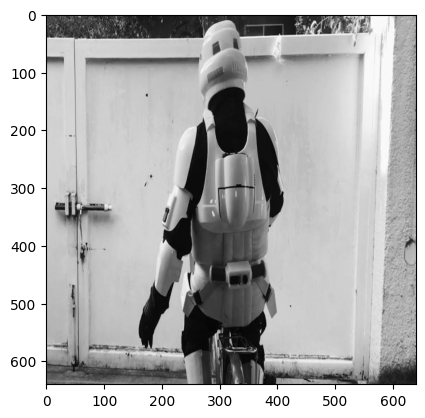

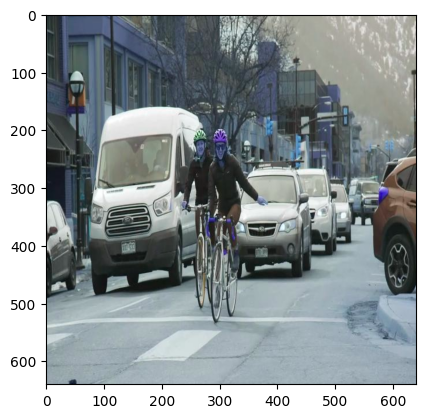

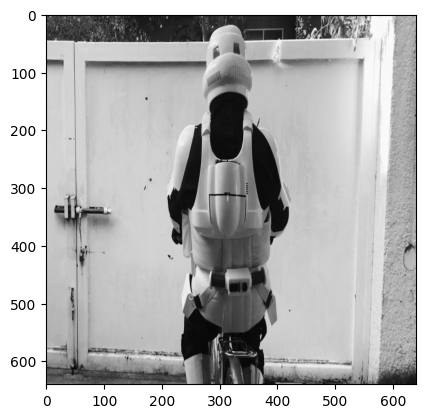

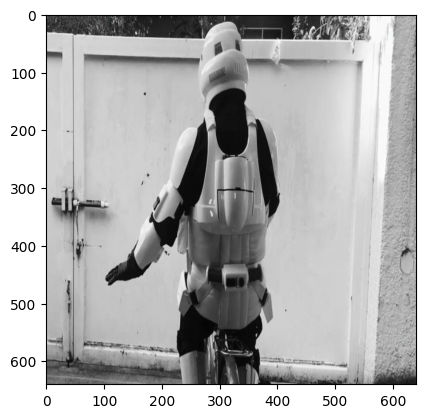

In [15]:
#visualize first four sample images from train data
for idx, image in enumerate(os.listdir(os.path.join(image_dir, "train"))):
    img = cv2.imread(os.path.join(image_dir,"train", image), 1)
    plt.imshow(img)
    plt.show()

    if idx == 3:
        break

## Creating Dataframe from txt labels
Creating Dataframes from txt files


In [21]:
class_names = ['Caution', 'Cyclist', 'Left Turn', 'Right Turn', 'Stop']

rows = []
for split in ['train', 'valid', 'test']:
    label_folder = f'{data_dir}/{split}/labels'
    for file in os.listdir(label_folder):
        if not file.endswith('.txt'):
            continue
        with open(os.path.join(label_folder, file)) as f:
            for line in f:
                parts = line.split()
                if len(parts) < 5:          # skip blank or malformed lines
                    continue
                rows.append({
                    'split': split,
                    'name': os.path.splitext(file)[0],
                    'class': int(parts[0]),
                    'x_center': float(parts[1]),
                    'y_center': float(parts[2]),
                    'box_width': float(parts[3]),
                    'box_height': float(parts[4]),
                })

df = pd.DataFrame(rows)
df['label'] = df['class'].map(dict(enumerate(class_names)))
#display(df.head())
display(df.sample(10, random_state=0))
print(df['split'].value_counts())


,split,name,class,x_center,y_center,box_width,box_height,label
0,train,2nd-Edited-mp4_frame1104_jpg.rf.d8ff7b982f4a1f...,1,0.390625,0.634375,0.157812,0.487500,Cyclist
1,train,2nd-Edited-mp4_frame1104_jpg.rf.d8ff7b982f4a1f...,1,0.051562,0.701562,0.103125,0.596875,Cyclist
2,train,2nd-Edited-mp4_frame4164_jpg.rf.ee23e2da58794d...,1,0.334375,0.428125,0.183594,0.728125,Cyclist
3,train,4th-vid-mp4_frame835_jpg.rf.d020d4311e95584be0...,2,0.367188,0.275000,0.142969,0.378125,Left Turn
4,train,4th-vid-mp4_frame835_jpg.rf.d020d4311e95584be0...,2,0.813281,0.270313,0.125781,0.384375,Left Turn


,split,name,class,x_center,y_center,box_width,box_height,label
7476,train,4th-vid-mp4_frame982_jpg.rf.e4f66aebac2c2c17f2...,1,0.401562,0.582812,0.126562,0.530469,Cyclist
6274,train,4th-vid-mp4_frame1264_jpg.rf.e36a666d16b66be11...,1,0.330469,0.473438,0.199219,0.942187,Cyclist
10004,valid,4th-vid-mp4_frame355_jpg.rf.518b0d0d005b6e2996...,2,0.613281,0.384375,0.139063,0.093750,Left Turn
6608,train,3rd-edited-mp4_frame495_jpg.rf.8d3b256d7a0fc29...,2,0.331250,0.414062,0.315625,0.153125,Left Turn
10250,test,1st-edited-mp4_frame90_jpg.rf.cbf0bb8184b25abe...,2,0.414062,0.463281,0.122656,0.082031,Left Turn
4391,train,2nd-Edited-mp4_frame2997_jpg.rf.76a17ffa1b49b8...,1,0.669531,0.532813,0.161719,0.888281,Cyclist
2876,train,2nd-Edited-mp4_frame5476_jpg.rf.d8bfbbdc8dd4ed...,0,0.373437,0.442969,0.087500,0.067187,Caution
2573,train,3rd-edited-mp4_frame4858_jpg.rf.f36dd20ab6758d...,0,0.746094,0.603906,0.132812,0.300781,Caution
6501,train,1st-edited-mp4_frame2133_jpg.rf.057aae76a1ccfc...,0,0.521875,0.487500,0.107031,0.269531,Caution
9267,valid,1st-edited-mp4_frame2146_jpg.rf.a091d216cfd9fb...,0,0.481250,0.490625,0.097656,0.305469,Caution


split
train    7800
valid    2256
test     1148
Name: count, dtype: int64


Sanity Check

In [23]:
# Class balance per split
print(df.groupby(['split', 'label']).size().unstack(fill_value=0), end="\n\n")

# Images with no boxes
n_labeled = df.groupby('split')['name'].nunique()
print(n_labeled, end="\n\n")

# Sanity check: bb between 0 and 1
print(df[['x_center', 'y_center', 'box_width', 'box_height']].describe())

label  Caution  Cyclist  Left Turn  Right Turn  Stop
split                                               
test       247      569         86         120   126
train     1674     3808        681         777   860
valid      448     1111        198         252   247

split
test      623
train    4316
valid    1260
Name: name, dtype: int64

           x_center      y_center     box_width    box_height
count  11204.000000  11204.000000  11204.000000  11204.000000
mean       0.483925      0.517520      0.167775      0.488912
std        0.170823      0.115574      0.092325      0.302894
min        0.051562      0.148438      0.010156      0.004687
25%        0.342187      0.448437      0.100000      0.214648
50%        0.457813      0.533594      0.150000      0.435937
75%        0.637500      0.595313      0.210938      0.776563
max        0.953125      0.976562      0.620313      1.000000


In [37]:
print('Train')
display(df[df['split'] == 'train'].sample(5))
print('\n\nVal')
display(df[df['split'] == 'valid'].sample(5))
print('\n\nTest')
display(df[df['split'] == 'test'].sample(5))



Train


,split,name,class,x_center,y_center,box_width,box_height,label
7025,train,4th-vid-mp4_frame855_jpg.rf.414ceabea2a3e77ac6...,2,0.401562,0.271875,0.079687,0.350000,Left Turn
6019,train,2nd-Edited-mp4_frame1009_jpg.rf.8cd449a5b26d9f...,1,0.495312,0.546875,0.037500,0.260937,Cyclist
7236,train,2nd-Edited-mp4_frame1042_jpg.rf.1582cba72ab4ba...,1,0.515625,0.626563,0.069531,0.410156,Cyclist
6361,train,1st-edited-mp4_frame1850_jpg.rf.537b78e80ccd39...,4,0.573438,0.424219,0.051562,0.126562,Stop
6790,train,3rd-edited-mp4_frame2363_jpg.rf.dbd596f7abb9b7...,0,0.685937,0.532031,0.158594,0.231250,Caution




Val


,split,name,class,x_center,y_center,box_width,box_height,label
8676,valid,4th-vid-mp4_frame502_jpg.rf.1083e54b551fabb1d7...,2,0.573438,0.488281,0.067187,0.082031,Left Turn
9955,valid,2nd-Edited-mp4_frame5589_jpg.rf.c85227d301f5f1...,0,0.421875,0.414062,0.088281,0.096875,Caution
9764,valid,2nd-Edited-mp4_frame554_jpg.rf.a19aec3b20aee63...,0,0.271875,0.482031,0.186719,0.141406,Caution
8053,valid,4th-vid-mp4_frame1342_jpg.rf.3feb7889cd8ba386b...,4,0.601562,0.615625,0.042188,0.128125,Stop
7931,valid,2nd-Edited-mp4_frame682_jpg.rf.7f1cecaf5194391...,1,0.300781,0.601562,0.167187,0.775000,Cyclist




Test


,split,name,class,x_center,y_center,box_width,box_height,label
10959,test,2nd-Edited-mp4_frame4283_jpg.rf.81fae51dbeec5a...,1,0.345313,0.447656,0.184375,0.715625,Cyclist
10881,test,2nd-Edited-mp4_frame2928_jpg.rf.8002c59106de55...,4,0.750781,0.696094,0.120313,0.607812,Stop
10958,test,3rd-edited-mp4_frame3965_jpg.rf.aa5e8d7e467e8e...,0,0.314063,0.671875,0.114844,0.278906,Caution
10839,test,4th-vid-mp4_frame1473_jpg.rf.031c8610fb16eb38c...,1,0.169531,0.603906,0.228906,0.791406,Cyclist
11046,test,2nd-Edited-mp4_frame5106_jpg.rf.172d2f791fffd2...,1,0.635938,0.540625,0.381250,0.910156,Cyclist


Visualizing one of the image in train set with the bounding box

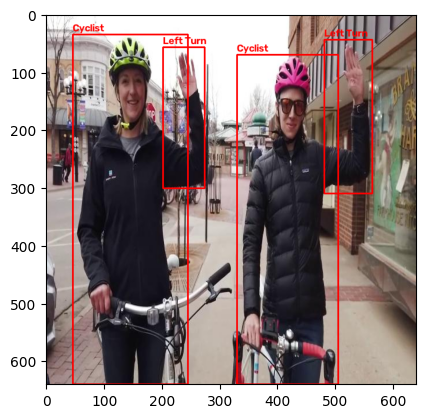

In [34]:


train_df = df[df['split'] == 'train'].reset_index(drop=True)   # so index 10 exists

index = 10
name = train_df.loc[index, 'name']

img = cv2.imread(f'{data_dir}/train/images/{name}.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)            # fix the blue-tint color order
h, w = img.shape[:2]

# All box for this image (an image can have several rows, cyclist plus hand signal)
for _, row in train_df[train_df['name'] == name].iterrows():
    x1 = int((row['x_center'] - row['box_width']  / 2) * w) #multiple as yolo label store coordinate as fraction
    y1 = int((row['y_center'] - row['box_height'] / 2) * h)
    x2 = int((row['x_center'] + row['box_width']  / 2) * w)
    y2 = int((row['y_center'] + row['box_height'] / 2) * h)

    cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)
    cv2.putText(img, str(row['label']), (x1, max(y1 - 5, 15)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)

plt.imshow(img)
plt.axis('on')
plt.show()

Checking to see if the above image has bounding boxes around other apples or not.

In [ ]:
train_df["name"][index]
filtered_df = train_df[train_df['name'] == train_df["name"][index]]
print(filtered_df)

        name  label  width  height  xmin  ymin  xmax  ymax
10  apple_18  apple    610     458   144   136   470   411


Checking to see the datatypes of all the columns and if there is any null value that needs to be eliminated from the data.

In [ ]:
val_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 117 entries, 0 to 116
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   name    117 non-null    object
 1   label   117 non-null    object
 2   width   117 non-null    int64 
 3   height  117 non-null    int64 
 4   xmin    117 non-null    int64 
 5   ymin    117 non-null    int64 
 6   xmax    117 non-null    int64 
 7   ymax    117 non-null    int64 
dtypes: int64(6), object(2)
memory usage: 7.4+ KB


What different types of labels are assigned to each sample and checking if they match the provided label/class information, i.e. there are no extra labels due to mistakes in spellings etc.

In [ ]:
print(train_df['label'].unique())
print(val_df['label'].unique())

['apple' 'banana' 'orange']
['banana' 'apple' 'orange']


We need to map labels to class_ids required for YOLO

In [ ]:
label_map = { 'orange': 0,
            'apple': 1,
            'banana': 2}

train_df['class'] = train_df['label'].map(label_map)
val_df['class'] = val_df['label'].map(label_map)

In [ ]:
train_df.head()

,name,label,width,height,xmin,ymin,xmax,ymax,class
0,apple_12,apple,450,428,43,21,350,353,1
1,apple_15,apple,1400,1046,643,364,1396,1046,1
2,apple_1,apple,0,0,8,15,331,349,1
3,apple_13,apple,800,800,415,261,720,567,1
4,apple_13,apple,800,800,105,426,393,691,1


convertig the bounding box format to the one required by YOLO:




In [ ]:
# Training data
train_df['x_center'] = (train_df['xmin']+train_df['xmax'])/(2*train_df["width"])
train_df['y_center'] = (train_df['ymin']+train_df['ymax'])/(2*train_df["height"])
train_df['box_width'] = (train_df['xmax']-train_df['xmin'])/ train_df["width"]
train_df['box_height'] = (train_df['ymax']-train_df['ymin'])/train_df["height"]

#Validation data
val_df['x_center'] = (val_df['xmin']+val_df['xmax'])/(2*val_df["width"])
val_df['y_center'] = (val_df['ymin']+val_df['ymax'])/(2*val_df["height"])
val_df['box_width'] = (val_df['xmax']-val_df['xmin'])/ val_df["width"]
val_df['box_height'] = (val_df['ymax']-val_df['ymin'])/val_df["height"]

In [ ]:
train_df.head()

,name,label,width,height,xmin,ymin,xmax,ymax,class,x_center,y_center,box_width,box_height
0,apple_12,apple,450,428,43,21,350,353,1,0.436667,0.436916,0.682222,0.775701
1,apple_15,apple,1400,1046,643,364,1396,1046,1,0.728214,0.673996,0.537857,0.652008
2,apple_1,apple,0,0,8,15,331,349,1,inf,inf,inf,inf
3,apple_13,apple,800,800,415,261,720,567,1,0.709375,0.517500,0.381250,0.382500
4,apple_13,apple,800,800,105,426,393,691,1,0.311250,0.698125,0.360000,0.331250


Deleting all the sample with Nan values in training and validation data

In [ ]:
#training
print("before deleting (train data): " , train_df.shape)
train_df.replace([np.inf, -np.inf], np.nan, inplace=True)
train_df.dropna(inplace=True)
print("after deleting(train_data): " ,train_df.shape)

#validation
print("before deleting (val data): " , val_df.shape)
val_df.replace([np.inf, -np.inf], np.nan, inplace=True)
val_df.dropna(inplace=True)
print("after deleting(val data): " , val_df.shape)



before deleting (train data):  (465, 13)
after deleting(train_data):  (420, 13)
before deleting (val data):  (117, 13)
after deleting(val data):  (110, 13)


converting the dataframe to type *str* (string) to be stored in text files.

In [ ]:
train_df = train_df.astype(str)
val_df = val_df.astype(str)

If there are more than one bounding boxes in single image, they should be written in one text file. As, you can see in the below example that one image has so many bounding boxes.

In [ ]:
filtered_df = train_df[train_df['name'] == train_df["name"][3]]
(filtered_df.head(15))

,name,label,width,height,xmin,ymin,xmax,ymax,class,x_center,y_center,box_width,box_height
3,apple_13,apple,800,800,415,261,720,567,1,0.709375,0.5175,0.38125,0.3825
4,apple_13,apple,800,800,105,426,393,691,1,0.31125,0.698125,0.36,0.33125
5,apple_13,apple,800,800,194,290,477,545,1,0.419375,0.521875,0.35375,0.31875


In [ ]:
#file_name = [x.split('.')[0] for x in df1["name"]]

#TRAINING DATA
#finding all the unique names:
unique_names= train_df['name'].unique()

#for each unique name, containing multiple bboxes, combine them together.
for name in unique_names:
  data = train_df[train_df.name == name]
  box_list = []
  for idx in range(len(data)):
        row = data.iloc[idx]
        box_list.append(row['class']+" "+row['x_center']+" "+row['y_center']+" "+ row['box_width']+" "+row['box_height'])

#writing on text files
  text = "\n".join(box_list)
  with open(f'{label_dir}/train/{name}.txt', 'w') as file:
            file.write(text)
#############################################################################################
#VALIDATION DATA
#finding all the unique names:
unique_names= val_df['name'].unique()

#for each unique name, containing multiple bboxes, combine them together.
for name in unique_names:
  data = val_df[val_df.name == name]
  box_list = []
  for idx in range(len(data)):
        row = data.iloc[idx]
        box_list.append(row['class']+" "+row['x_center']+" "+row['y_center']+" "+ row['box_width']+" "+row['box_height'])

#writing on text files
  text = "\n".join(box_list)
  with open(f'{label_dir}/val/{name}.txt', 'w') as file:
            file.write(text)

## Checking Missing Files

Checking the folders if every image file has a corresponding label file


(We will copy the code, we already used in previous turorial after updating)

In [ ]:
#The lists of all the images and labels for train and validation set:
train_images=glob.glob(os.path.join(image_dir, "train",'*.jpg'))
train_labels=glob.glob(os.path.join(label_dir, "train",'*.txt'))
val_images=glob.glob(os.path.join(image_dir, "val",'*.jpg'))
val_labels=glob.glob(os.path.join(label_dir, "val",'*.txt'))
#print(val_labels)

# Get the list of filenames without extensions
image_files_train = {file.split("/")[-1].split(".")[0] for file in train_images}
label_files_train = {file.split("/")[-1].split(".")[0] for file in train_labels}

image_files_val = {file.split("/")[-1].split(".")[0] for file in val_images}
label_files_val = {file.split("/")[-1].split(".")[0] for file in val_labels}
#print(image_files_val)



In [ ]:
print(len(image_files_val), "  =  ", len(label_files_val))

56   =   56


In [ ]:
print(len(image_files_train), "  =  ", len(label_files_train))

207   =   207


In [ ]:
# Find extra files in each folder

#TRAINING DATA
extra_images_train = image_files_train - label_files_train
extra_labels_train = label_files_train - image_files_train

# Output the results
print(f"Training Extra images (without corresponding labels): {extra_images_train}")
print(f"Training Extra labels (without corresponding images): {extra_labels_train}")


#VALIDATION DATA
extra_images_val = image_files_val - label_files_val
extra_labels_val = label_files_val - image_files_val

# Output the results
print(f"Validation Extra images (without corresponding labels): {extra_images_val}")
print(f"Validation Extra labels (without corresponding images): {extra_labels_val}")

Training Extra images (without corresponding labels): {'banana_71', 'apple_28', 'orange_42', 'orange_35', 'orange_51', 'orange_64', 'orange_30', 'orange_22', 'apple_8', 'banana_57', 'banana_72', 'banana_53', 'orange_11', 'banana_75', 'banana_60', 'orange_59', 'orange_50', 'orange_70', 'mixed_16', 'banana_35', 'orange_13', 'orange_18', 'orange_4', 'apple_43', 'apple_20', 'apple_42', 'apple_44', 'apple_1', 'banana_25', 'orange_1', 'apple_17', 'apple_37', 'orange_68'}
Training Extra labels (without corresponding images): set()
Validation Extra images (without corresponding labels): {'apple_79', 'banana_87', 'apple_92', 'orange_94'}
Validation Extra labels (without corresponding images): set()


Make sure that the above info is correct by chceking the data manually.

Now removing from the dataset:

In [ ]:
for file in extra_images_train:
     os.remove(os.path.join(image_dir, "train", file + '.jpg')) # or '.png' depending on your image format

for file in extra_images_val:
     os.remove(os.path.join(image_dir, "val", file + '.jpg'))

Now run the above cells again to find if all the missing data is deleted.

# Custom object detection using YOLO

First install and import

In [ ]:
%pip install ultralytics
import ultralytics
ultralytics.checks()

Ultralytics 8.4.76 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 47.2/112.6 GB disk)


In [ ]:
from ultralytics import YOLO

## Training YOLO

We are going to select small pretrained (on COCO dataset) model of YOLOv8

In [ ]:
model = YOLO('yolov8s.pt') # pretrained model

The detailed architecture of the model can be seen from:


In [ ]:
model

YOLO(
  (model): DetectionModel(
    (model): Sequential(
      (0): Conv(
        (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (1): Conv(
        (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (2): C2f(
        (cv1): Conv(
          (conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (cv2): Conv(
          (conv): Conv2d(96, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_s

In [ ]:
%%writefile config.yaml
path: /content/drive/MyDrive/Tutorials/Datasets/FRUIT DATA/Final_data
train: /content/drive/MyDrive/Tutorials/Datasets/FRUIT DATA/Final_data/images/train
#test: (test dataset folder path)
val: /content/drive/MyDrive/Tutorials/Datasets/FRUIT DATA/Final_data/images/val

# Classes
nc: 3 # replace based on your dataset's number of classes

# Class names
# replace all class names with your own classes' names
names:
  0: orange
  1: apple
  2: banana

Overwriting config.yaml


Please look at [Yolo train Docs](https://docs.ultralytics.com/modes/train/#train-settings) for hyperparameters for model tuning and configuration, e.g. lr0, imgsz, model etc.

In [ ]:
model.train(data="config.yaml",epochs=5,patience=5,batch=8, lr0=0.0005,imgsz=640,project="/content/drive/MyDrive/custom_folder")

Ultralytics 8.4.76 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=config.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=5, perspective=0.0, pl

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x781904201cd0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

## Evaluation Metrics

[This](https://docs.ultralytics.com/guides/yolo-performance-metrics/) is a very good detailed explanation of different perfromance metrics in YOLO.

**Choosing the Right Metrics**

Choosing the right metrics to evaluate often depends on the specific application.

- mAP: Suitable for a broad assessment of model performance.

- IoU: Essential when precise object location is crucial.

- Precision: Important when minimizing false detections is a priority.

- Recall: Vital when it's important to detect every instance of an object.

- F1 Score: Useful when a balance between precision and recall is needed.


In [ ]:
metrics = model.val(project="/content/drive/MyDrive/custom_folder")  # no other arguments needed, dataset and settings remembered
metrics.box.map    # map50-95
metrics.box.map50  # map50
metrics.box.map75  # map75
metrics.box.maps   # a list contains map50-95 of each category
metrics.box.mp    # P
metrics.box.mr    # R

Ultralytics 8.4.76 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 11,126,745 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.7±0.3 ms, read: 27.6±22.4 MB/s, size: 49.7 KB)
val: Scanning /content/drive/MyDrive/Tutorials/Datasets/FRUIT DATA/Final_data/labels/val.cache... 56 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 56/56 19.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.5it/s 2.7s
                   all         56        110      0.689      0.766      0.776      0.552
                orange         21         41      0.743      0.927      0.925      0.688
                 apple         22         33      0.717      0.788      0.805      0.639
                banana         21         36      0.607      0.583      0.598       0.33
Speed: 10.2ms preprocess, 9.4ms inference, 0.0ms loss, 3.2ms postprocess per image
Results saved to

np.float64(0.7660137965016015)

Showing confusion matrix, that is already stored in detect/train folder

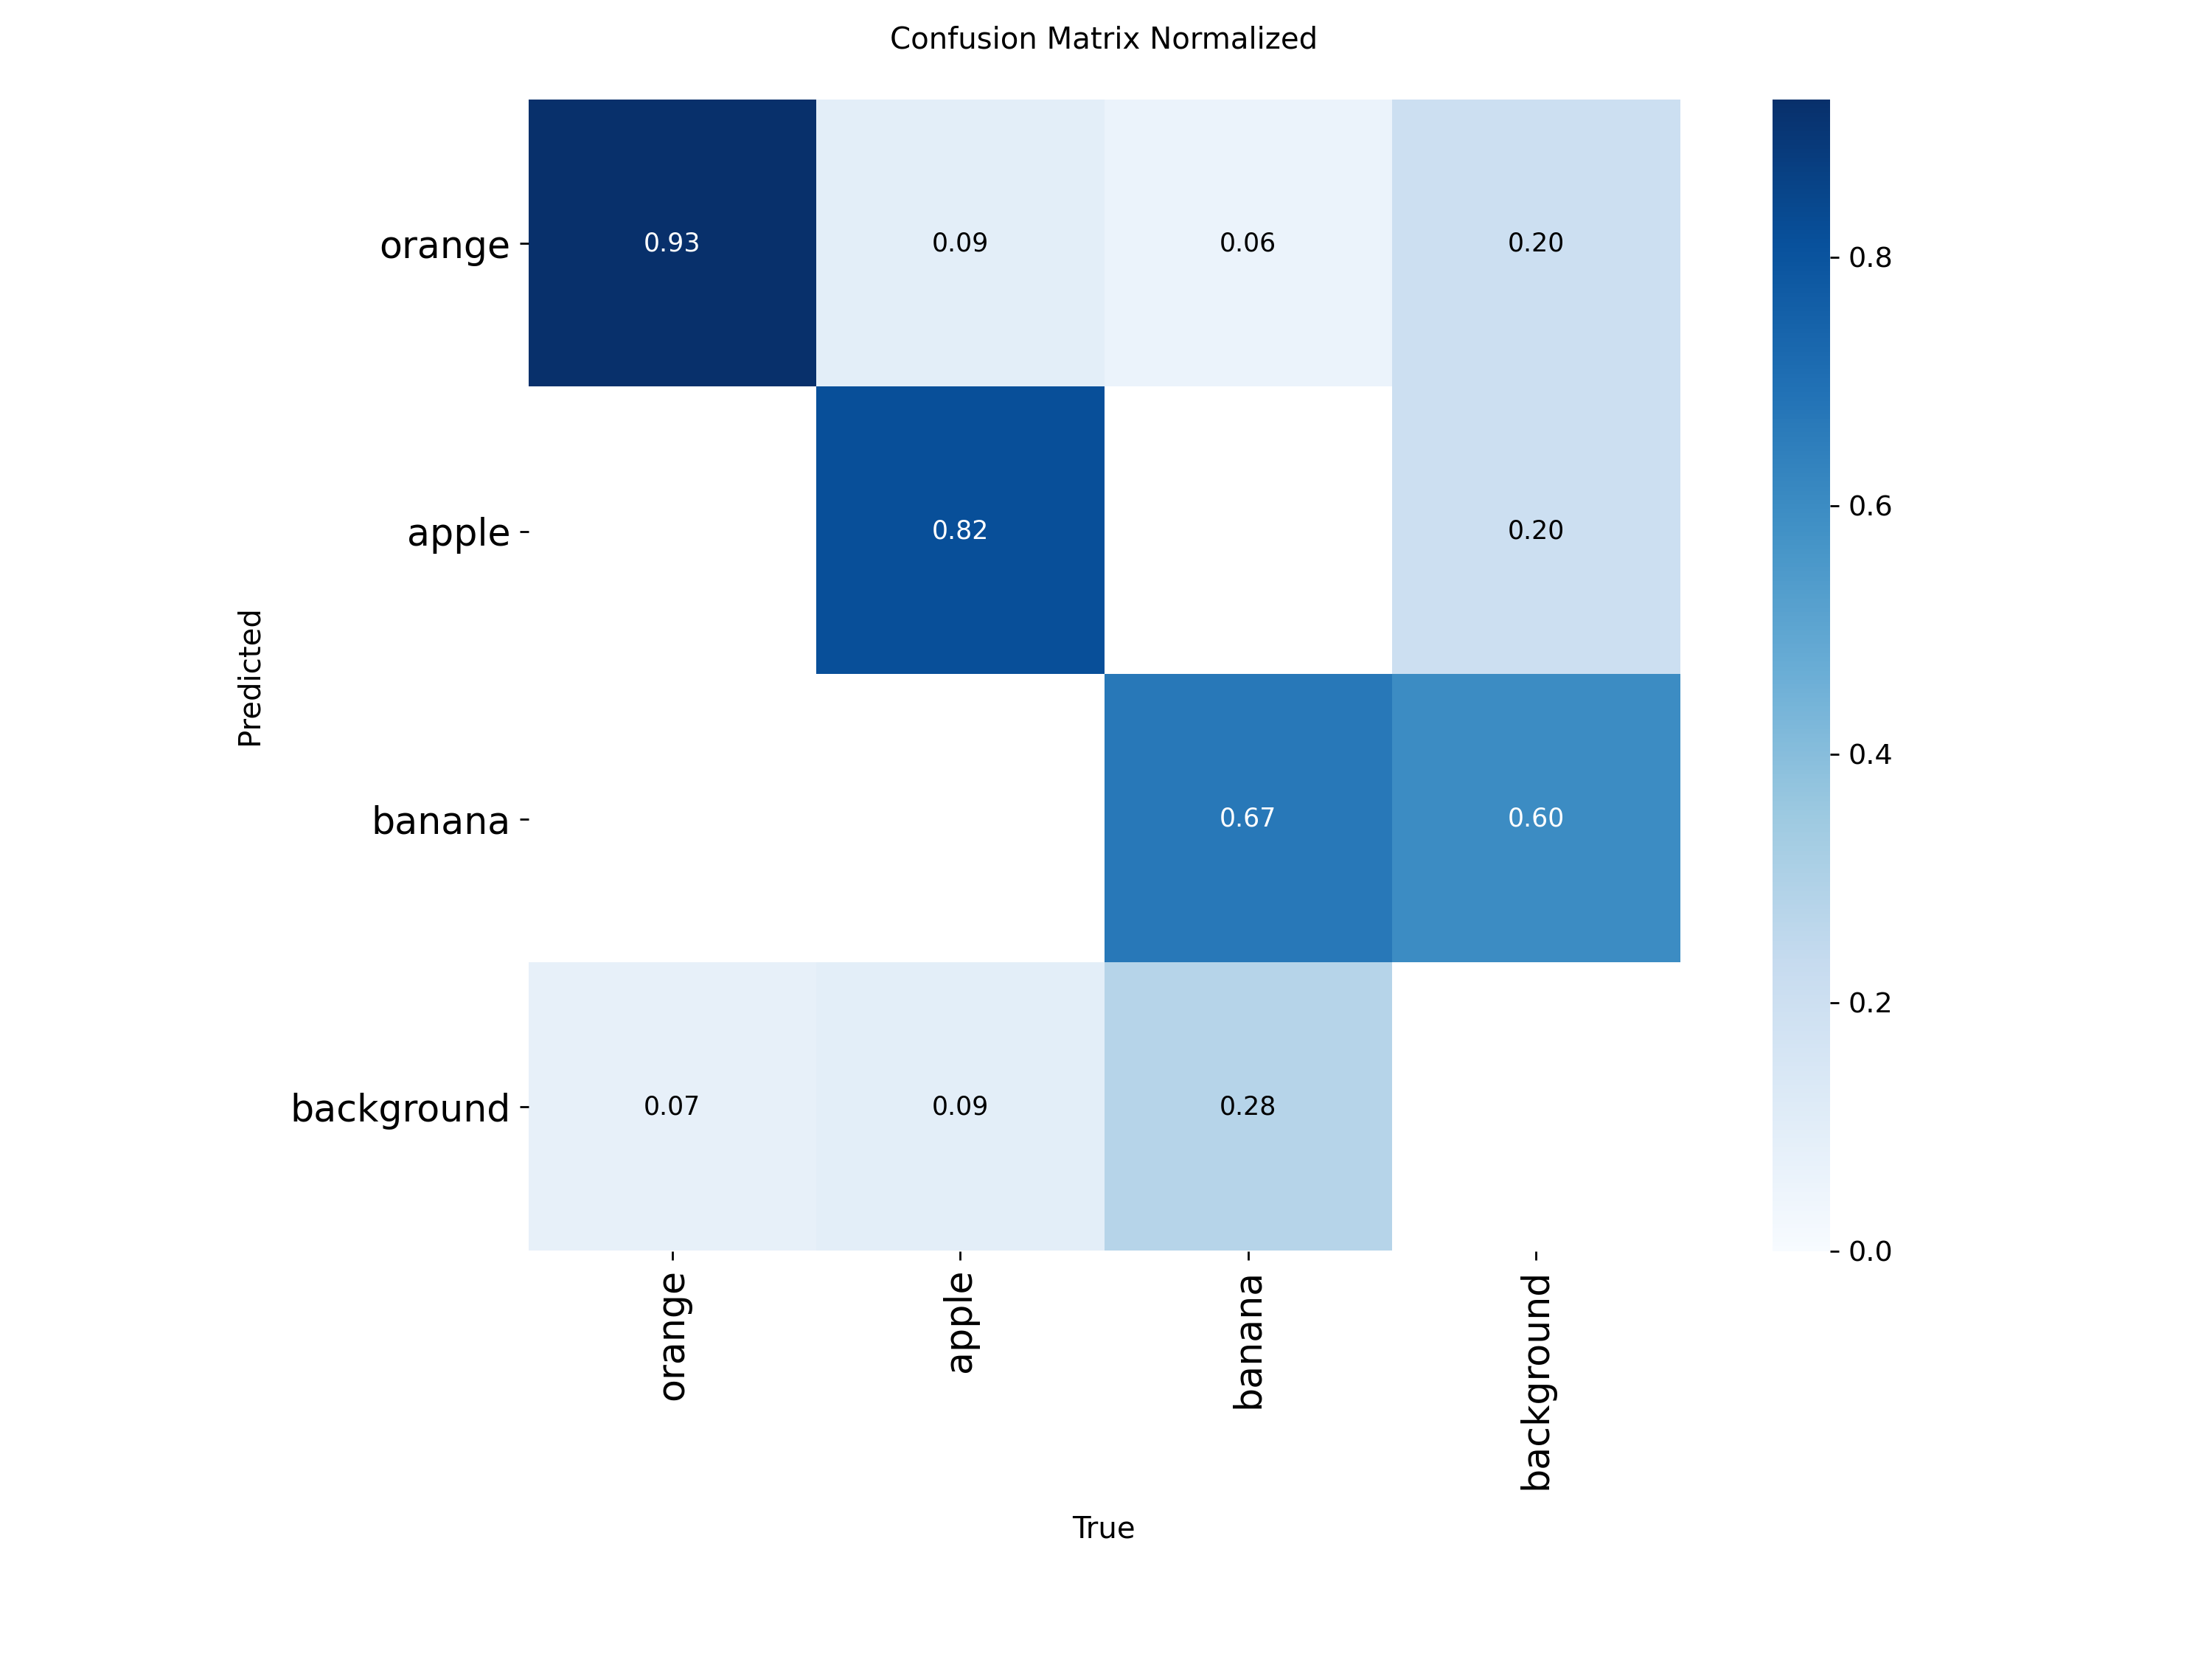

In [ ]:
%matplotlib inline
from PIL import Image

Image.open('/content/drive/MyDrive/custom_folder/train/confusion_matrix_normalized.png')

##Prediction

In [ ]:
model = YOLO("/content/drive/MyDrive/custom_folder/my_experiment/weights/best.pt")  # load a custom model

# Predict with the model with any image from internet?
results = model('https://www.freshpoint.com/wp-content/uploads/2019/08/freshpoint-produce-101-apples-bananas.jpg', save=True, project="/content/drive/MyDrive/custom_folder")


Found https://www.freshpoint.com/wp-content/uploads/2019/08/freshpoint-produce-101-apples-bananas.jpg locally at freshpoint-produce-101-apples-bananas.jpg
image 1/1 /content/freshpoint-produce-101-apples-bananas.jpg: 576x640 2 apples, 3 bananas, 16.4ms
Speed: 2.3ms preprocess, 16.4ms inference, 1.7ms postprocess per image at shape (1, 3, 576, 640)
Results saved to /content/drive/MyDrive/custom_folder/predict-2


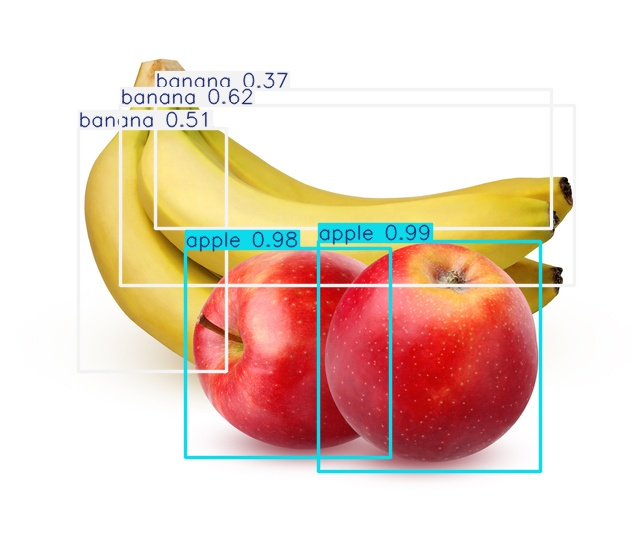

In [ ]:
# SHOW THE IMAGE STORED
%matplotlib inline
from PIL import Image

Image.open('/content/drive/MyDrive/custom_folder/predict-2/freshpoint-produce-101-apples-bananas.jpg')